# E3 — Khi nào nên retrain? Tín hiệu nào phát hiện drift tốt nhất?

**Notebook học theo từng bước** của giai đoạn 5. Đọc cùng: [`../PHUONG-PHAP.md`](../PHUONG-PHAP.md) (khung 7 bước) và [`../E1-chi-so-danh-gia.md`](../E1-chi-so-danh-gia.md) (đã chọn họ MAE/WAPE để theo dõi).

**Cách dùng trong VS Code:** chọn kernel `.venv`, chạy từng ô bằng **Shift + Enter**. Mỗi phần có: **Đang làm gì** → **Đoán trước** → ô code → **Đọc kết quả**.

| Bước nhỏ | Nội dung | Trạng thái |
| --- | --- | --- |
| **5.1** | Chạy lại đúng cách phát hiện drift của hệ thống trên dữ liệu thật | Xong |
| **5.2** | Dựng "đáp án": lúc nào retrain thật sự có lợi | Xong |
| **5.3** | Tính 5 tín hiệu trên cùng dòng thời gian | Chưa |
| **5.4** | Chấm: độ trễ, báo nhầm, bỏ sót; drift giả lập | Chưa |
| **5.5** | Chọn tín hiệu, ngưỡng; lợi ích khi retrain; báo cáo | Chưa |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "real").is_dir())
sys.path.insert(0, str(ROOT))
FIG = ROOT / "experiments" / "figures"
pd.set_option("display.precision", 2)
BLUE, ORANGE, INK, MUTED = "#257de0", "#f47230", "#191919", "#666666"   # bảng màu đã kiểm (dataviz)
print("Thư mục dự án:", ROOT)

Thư mục dự án: D:\You Are Here\HK_VII\KLTN\Project\main_project


---
## Bước 5.1 — Hệ thống đang phát hiện drift thế nào, và nó có đúng không?

**Đang làm gì.** Trước khi đề xuất cách mới, phải **đo cách đang có**. Ta không viết lại thuật toán; ta **gọi đúng hàm của hệ thống** (`src/feature_drift.py`) với **đúng cấu hình** (`backend/app/core/config.py`) và chọn cửa sổ dữ liệu **y như** `backend/app/services/drift_monitoring.py::_check_region`.

**Cách hệ thống làm (lời thường).** Mỗi ngày lúc 00:00:
1. **Kỳ tham chiếu** = 30 ngày **ngay trước** `train_end_date` của model active. Kỳ này **đứng yên** cho đến khi có model mới được Activate.
2. **Kỳ hiện tại** = 7 ngày gần nhất.
3. Với **13 cột thời tiết/ngày lễ** (không xét `traffic_volume`), so phân bố hai kỳ: cột số dùng **PSI** (chia 10 khoảng theo kỳ tham chiếu, đo tỉ lệ giờ rơi vào mỗi khoảng thay đổi bao nhiêu), cột chữ dùng **JS divergence**.
4. Cột nào vượt ngưỡng (PSI > 0,2; JS > 0,15) là "drift"; **từ 2 cột trở lên** → báo drift → có thể tự retrain (nghỉ 72 giờ giữa hai lần).

Ví dụ đời thường: muốn biết học sinh có sa sút không, nhưng chỉ xem **thời tiết tuần này khác tháng trước** chứ không xem **điểm thi**.

In [2]:
from backend.app.core.config import get_settings
from src.feature_drift import calculate_feature_drift

S = get_settings()
pd.Series({"Kỳ hiện tại (ngày)": S.drift_window_days, "Kỳ tham chiếu (ngày)": S.drift_reference_days,
           "Số giờ tối thiểu mỗi kỳ": S.drift_min_window_rows, "Ngưỡng PSI (cột số)": S.drift_psi_threshold,
           "Ngưỡng JS (cột chữ)": S.drift_js_threshold, "Số cột vượt ngưỡng để báo": S.drift_min_drifted_features,
           "Nghỉ giữa hai lần retrain (giờ)": S.drift_retrain_cooldown_hours,
           "Tự Activate model mới": S.drift_auto_promote}, name="Cấu hình đang chạy").to_frame()

,Cấu hình đang chạy
Kỳ hiện tại (ngày),7
Kỳ tham chiếu (ngày),30
Số giờ tối thiểu mỗi kỳ,168
Ngưỡng PSI (cột số),0.2
Ngưỡng JS (cột chữ),0.15
Số cột vượt ngưỡng để báo,2
Nghỉ giữa hai lần retrain (giờ),72
Tự Activate model mới,False


**Hàm chạy lại một lần kiểm.** Chép đúng cách chọn cửa sổ của `_check_region` (đọc CSV như `_download_dataset_frame`: `read_csv` mặc định rồi đổi `date_time`), rồi gọi hàm của hệ thống. Ta thêm một con số để quan sát: **lưu lượng trung bình kỳ hiện tại ÷ kỳ tham chiếu** (hệ thống **không** dùng số này).

In [3]:
def load(path):
    frame = pd.read_csv(ROOT / path)
    frame["date_time"] = pd.to_datetime(frame["date_time"], errors="raise")
    return frame.sort_values("date_time")

def check(frame, train_end, current_end):
    """Một lần kiểm drift, chọn cửa sổ y như drift_monitoring._check_region."""
    train_end, current_end = pd.Timestamp(train_end), pd.Timestamp(current_end)
    reference = frame[(frame.date_time >= train_end - pd.Timedelta(days=S.drift_reference_days))
                      & (frame.date_time < train_end)]
    production = frame[frame.date_time >= train_end]
    if production.empty or not production.date_time.min() <= current_end <= production.date_time.max():
        return {"status": "skipped"}
    current = production[(production.date_time > current_end - pd.Timedelta(days=S.drift_window_days))
                         & (production.date_time <= current_end)]
    if min(len(reference), len(current)) < S.drift_min_window_rows:
        return {"status": "skipped"}                     # thiếu giờ (dữ liệu có lỗ) -> hệ thống bỏ qua
    report = calculate_feature_drift(reference, current, numeric_threshold=S.drift_psi_threshold,
                                     categorical_threshold=S.drift_js_threshold,
                                     min_drifted_features=S.drift_min_drifted_features)
    return {"status": "drift" if report["summary"]["drift_detected"] else "stable",
            "drifted_count": report["summary"]["drifted_feature_count"],
            "drifted": [k for k, v in report["features"].items() if v["drift"]],
            "traffic_ratio": current.traffic_volume.mean() / reference.traffic_volume.mean()}

def daily(frame, train_end, days):
    """Kiểm mỗi ngày lúc 00:00, bắt đầu khi kỳ hiện tại đã đủ 7 ngày sau train_end."""
    start = pd.Timestamp(train_end) + pd.Timedelta(days=S.drift_window_days)
    return pd.DataFrame([{"day": day, **check(frame, train_end, day)}
                         for day in pd.date_range(start, periods=days, freq="D")])

glasgow = load("data/real/glasgow/TrafficVolumeData_Glasgow_GD1351_R_2019_2023.csv")
i94 = load("data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv")
print("Đã nạp:", len(glasgow), "giờ Glasgow,", len(i94), "giờ I-94")

Đã nạp: 33643 giờ Glasgow, 40575 giờ I-94


### 5.1a — Drift thật: COVID ở Glasgow

Giả sử model được train đến **01/03/2020** (kỳ tham chiếu = tháng 2/2020). Anh phong tỏa toàn quốc từ **23/03/2020**; ở E0 ta đã thấy lưu lượng Glasgow tụt mạnh. Đây là **drift thật, biết ngày bắt đầu**.

> **Đoán trước:**
> 1. Hệ thống có báo drift khi COVID xảy ra không?
> 2. Nó báo **trước** hay **sau** 23/03? Vì sao?

In [4]:
LOCKDOWN = pd.Timestamp("2020-03-23")
g = daily(glasgow, "2020-03-01", 115)
checked = g[g.status != "skipped"]
print("Số ngày kiểm:", len(g), "| bỏ qua vì thiếu giờ:", (g.status == "skipped").sum(),
      "| báo drift:", (checked.status == "drift").sum(), "/", len(checked))
print("Lần báo drift đầu tiên:", checked[checked.status == "drift"].day.min().date(), "(phong tỏa:", LOCKDOWN.date(), ")")
before = checked[checked.day < LOCKDOWN]
print("Trước phong tỏa: lưu lượng = %.2f lần kỳ tham chiếu, vẫn báo drift %d/%d ngày"
      % (before.traffic_ratio.mean(), (before.status == "drift").sum(), len(before)))
cols = pd.Series([c for row in checked.drifted for c in row]).value_counts()
(cols / len(checked) * 100).round(0).rename("% ngày cột này vượt ngưỡng").to_frame().T

Số ngày kiểm: 115 | bỏ qua vì thiếu giờ: 27 | báo drift: 88 / 88
Lần báo drift đầu tiên: 2020-03-08 (phong tỏa: 2020-03-23 )
Trước phong tỏa: lưu lượng = 1.10 lần kỳ tham chiếu, vẫn báo drift 8/8 ngày


,wind_speed,wind_direction,temperature,dew_point,humidity,rain_p_h,air_pollution_index,clouds_all,weather_description,weather_type
% ngày cột này vượt ngưỡng,100.0,100.0,100.0,99.0,97.0,92.0,81.0,53.0,42.0,31.0


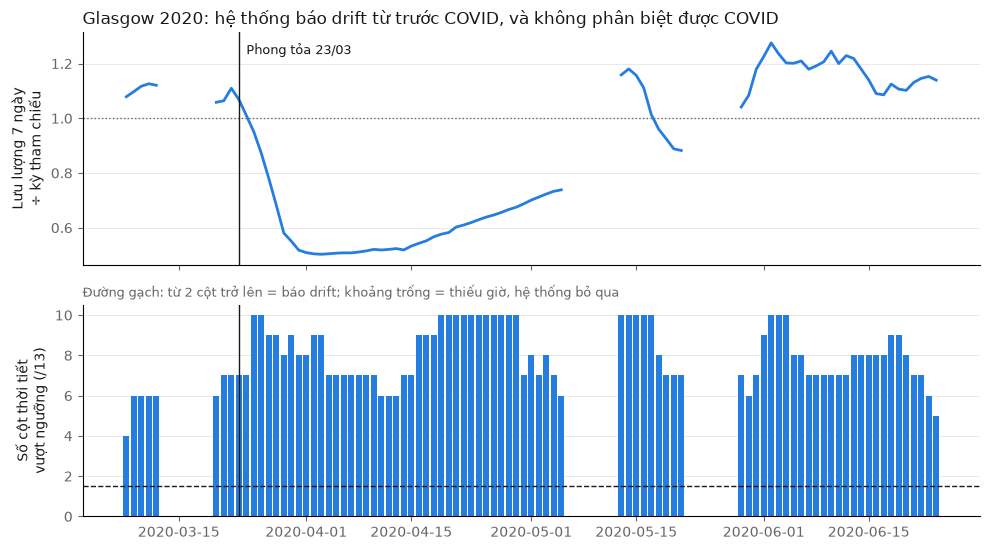

In [5]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.1, 1]})
top.plot(g.day, g.traffic_ratio, color=BLUE, lw=2)
top.axhline(1, color=MUTED, lw=1, ls=":")
top.set_ylabel("Lưu lượng 7 ngày\n÷ kỳ tham chiếu", color=INK)
top.set_title("Glasgow 2020: hệ thống báo drift từ trước COVID, và không phân biệt được COVID", loc="left", color=INK)
bottom.bar(checked.day, checked.drifted_count, width=0.8, color=BLUE)
bottom.axhline(S.drift_min_drifted_features - 0.5, color=INK, lw=1, ls="--")
bottom.set_title("Đường gạch: từ 2 cột trở lên = báo drift; khoảng trống = thiếu giờ, hệ thống bỏ qua", loc="left", fontsize=9, color=MUTED)
bottom.set_ylabel("Số cột thời tiết\nvượt ngưỡng (/13)", color=INK)
for ax in (top, bottom):
    ax.axvline(LOCKDOWN, color=INK, lw=1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
top.text(LOCKDOWN + pd.Timedelta(days=1), top.get_ylim()[1] * 0.97, "Phong tỏa 23/03", va="top", color=INK, fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "E3-1-glasgow-covid-feature-drift.png", dpi=150)
plt.show()

**Đọc kết quả.**
- Hệ thống **báo drift ngay lần kiểm đầu tiên (08/03)**, hai tuần **trước** phong tỏa, khi lưu lượng vẫn **cao hơn** kỳ tham chiếu (≈ 1,1 lần). Lý do: thời tiết đầu tháng 3 khác tháng 2 (gió, nhiệt độ, điểm sương…).
- Từ đó **ngày nào cũng báo** (88/88 ngày kiểm được; khoảng trống trên hình là những ngày thiếu giờ dữ liệu nên hệ thống bỏ qua).
- Sau phong tỏa, số cột vượt ngưỡng có lúc lên 9–10, nhưng **giữa tháng 5 và đầu tháng 6 cũng lên 10** trong khi lưu lượng đã trở lại ≈ 1,1–1,2 lần tham chiếu. Con số này **đi theo thời tiết** (càng xa tháng 2 càng khác mùa), không đi theo giao thông.
- Nghĩa là: tín hiệu **có báo** trong thời gian COVID, nhưng **không phải vì COVID**. Nó không phân biệt được "giao thông thay đổi thật" với "trời đổi mùa". Người vận hành nhìn cảnh báo này không biết model có thật sự kém đi không.

### 5.1b — Dữ liệu ổn định: I‑94 qua 36 tháng

Nếu ở nơi giao thông **ổn định** mà hệ thống vẫn báo, đó là **báo nhầm**. Thử 36 mốc train khác nhau (ngày 1 hằng tháng, 2013–2017), mỗi mốc kiểm hằng ngày trong 90 ngày.

> **Đoán trước:** trong dữ liệu ổn định, bao nhiêu % ngày kiểm bị báo drift? Sau bao nhiêu ngày thì lần báo đầu tiên xuất hiện?

In [6]:
rows = []
for train_end in pd.date_range("2013-01-01", "2017-09-01", freq="MS"):
    d = daily(i94, train_end, 90)
    d = d[d.status != "skipped"]                     # I-94 có nhiều lỗ dữ liệu -> nhiều ngày bị bỏ qua
    if d.empty:
        continue
    alarms = d[d.status == "drift"]
    rows.append({"train_end": train_end.date(), "ngày kiểm được": len(d),
                 "% ngày báo drift": 100 * len(alarms) / len(d),
                 "lần báo đầu sau (ngày)": (alarms.day.min() - train_end).days if len(alarms) else None,
                 "lưu lượng ÷ tham chiếu (trung vị)": d.traffic_ratio.median()})
i94_months = pd.DataFrame(rows)
print("Số mốc train có ngày kiểm được:", len(i94_months))
i94_months.describe().loc[["mean", "min", "50%", "max"]].round(2)

Số mốc train có ngày kiểm được: 36


,ngày kiểm được,% ngày báo drift,lần báo đầu sau (ngày),lưu lượng ÷ tham chiếu (trung vị)
mean,36.89,100.0,23.89,1.02
min,3.00,100.0,7.00,0.82
50%,40.00,100.0,9.00,1.03
max,76.00,100.0,94.00,1.13


**Đọc kết quả.**
- **100% ngày kiểm được đều báo drift**, ở cả 36 mốc train, dù lưu lượng gần như không đổi (trung vị ≈ 1,0 lần kỳ tham chiếu).
- Một nửa số mốc báo ngay trong **≤ 9 ngày** sau khi train (lần kiểm đầu tiên là ngày thứ 7).
- Nếu bật tự retrain, hệ thống sẽ retrain **mỗi 72 giờ** (hết thời gian nghỉ là báo lại) — tốn tài nguyên mà không vì lý do thật.

### 5.1c — Kiểm chứng âm: khi chắc chắn **không** có drift

Có thể ai đó nói: "biết đâu thời tiết thật sự đổi". Để chắc, ta dựng một tình huống **chắc chắn không có drift**: lấy kỳ hiện tại là **7 ngày cuối nằm bên trong chính kỳ tham chiếu**. Một bộ phát hiện tốt phải gần như **không** báo.

> **Đoán trước:** bao nhiêu % lần kiểm vẫn báo drift?

In [7]:
def null_test(frame, ends):
    rows = []
    for end in ends:
        reference = frame[(frame.date_time >= end - pd.Timedelta(days=30)) & (frame.date_time < end)]
        current = reference[reference.date_time >= end - pd.Timedelta(days=7)]   # nằm trong tham chiếu
        if min(len(reference), len(current)) < S.drift_min_window_rows:
            continue
        r = calculate_feature_drift(reference, current, S.drift_psi_threshold, S.drift_js_threshold,
                                    S.drift_min_drifted_features)
        rows.append({"drift": r["summary"]["drift_detected"], "count": r["summary"]["drifted_feature_count"],
                     **{k: v["drift"] for k, v in r["features"].items()}})
    return pd.DataFrame(rows)

hcm = load("data/synthetic/TrafficVolumeData_HCM_2015_2030_synthetic.csv")
null = {"I-94 (thật)": null_test(i94, pd.date_range("2013-01-01", "2018-09-01", freq="7D")),
        "Glasgow (thật)": null_test(glasgow, pd.date_range("2019-11-01", "2023-09-01", freq="7D")),
        "Hồ Chí Minh (synthetic)": null_test(hcm, pd.date_range("2016-01-01", "2026-01-01", freq="7D"))}
pd.DataFrame({name: {"số lần kiểm": len(t), "% báo drift (lẽ ra ≈ 0%)": 100 * t.drift.mean(),
                     "số cột vượt ngưỡng (trung vị)": t["count"].median()} for name, t in null.items()}).T.round(1)

,số lần kiểm,% báo drift (lẽ ra ≈ 0%),số cột vượt ngưỡng (trung vị)
I-94 (thật),96.0,97.9,4.0
Glasgow (thật),172.0,98.3,5.0
Hồ Chí Minh (synthetic),522.0,61.3,2.0


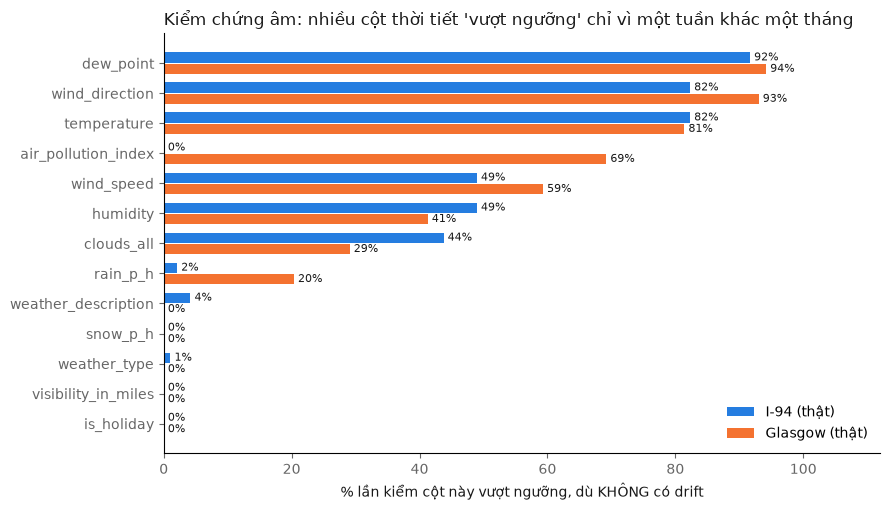

,I-94 (thật),Glasgow (thật)
is_holiday,0.0,0.0
visibility_in_miles,0.0,0.0
weather_type,1.0,0.0
snow_p_h,0.0,0.0
weather_description,4.0,0.0
rain_p_h,2.0,20.0
clouds_all,44.0,29.0
humidity,49.0,41.0
wind_speed,49.0,59.0
air_pollution_index,0.0,69.0


In [8]:
features = [c for c in null["I-94 (thật)"].columns if c not in ("drift", "count")]
share = pd.DataFrame({name: 100 * null[name][features].mean() for name in ["I-94 (thật)", "Glasgow (thật)"]})
share = share.sort_values("Glasgow (thật)")
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(share)); h = 0.38
for offset, (name, color) in zip((h / 2, -h / 2), [("I-94 (thật)", BLUE), ("Glasgow (thật)", ORANGE)]):
    bars = ax.barh(y + offset, share[name], height=h - 0.04, color=color, label=name)
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8, color=INK)
ax.set_yticks(y, share.index); ax.set_xlim(0, 112)
ax.set_xlabel("% lần kiểm cột này vượt ngưỡng, dù KHÔNG có drift", color=INK)
ax.set_title("Kiểm chứng âm: nhiều cột thời tiết 'vượt ngưỡng' chỉ vì một tuần khác một tháng", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(colors=MUTED)
fig.tight_layout(); fig.savefig(FIG / "E3-2-null-test-feature-share.png", dpi=150); plt.show()
share.round(0)

**Đọc kết quả.**
- Ngay cả khi **chắc chắn không có drift**, hệ thống vẫn báo ở **≈ 98%** lần kiểm với dữ liệu thật (I‑94, Glasgow) và ≈ 61% với dữ liệu synthetic của website.
- Nguyên nhân là cách đo, không phải dữ liệu: **thời tiết của một tuần tự nhiên khác thời tiết của cả tháng** (một tuần có thể mưa liền, gió một hướng). PSI trên 168 giờ liền nhau, chia 10 khoảng, gần như luôn vượt 0,2 với các cột như nhiệt độ, điểm sương, gió; cần chỉ 2/13 cột là đủ báo.
- Cột nào trống hoặc hằng số (ví dụ `air_pollution_index`, `visibility_in_miles` = 0 ở I‑94) thì không bao giờ vượt — chúng không giúp gì.

### 5.1d — Trên hệ thống thật (đọc DB chỉ đọc, 27/11/2026)

Bảng `drift_checks` của website (Hà Nội, Hồ Chí Minh; dataset synthetic) có **12 lần kiểm**: 3 lần bỏ qua (kỳ hiện tại chưa đủ 168 giờ), **9/9 lần còn lại đều báo drift** (4–6/13 cột), trong đó 2 lần đã kích hoạt retrain (12/11 tự động, 17/11 thủ công). Lần kiểm 25 và 27/11 của Hồ Chí Minh so tuần hiện tại với kỳ tham chiếu **tháng 12/2025** (model train đến 01/01/2026) — lệch gần một năm, khác mùa.

*Số này lấy một lần bằng truy vấn chỉ đọc trong pod API; notebook không kết nối hệ thống nên không chạy lại được ô này.*

### Tóm tắt bước 5.1

| Câu hỏi | Trả lời bằng số |
| --- | --- |
| COVID ở Glasgow có được phát hiện **vì** COVID không? | Không: báo từ 08/03 (trước phong tỏa 15 ngày), lưu lượng lúc đó còn cao hơn tham chiếu; tín hiệu không đổi khi lưu lượng tụt một nửa |
| Dữ liệu ổn định (I‑94) bị báo nhầm bao nhiêu? | 100% ngày kiểm, ở cả 36 mốc train; một nửa báo trong ≤ 9 ngày |
| Khi chắc chắn không có drift? | Vẫn báo ≈ 98% (thật), ≈ 61% (synthetic) |
| Hệ thống thật? | 9/9 lần kiểm không bị bỏ qua đều báo drift |

**Kết luận 5.1:** cách phát hiện drift hiện tại **luôn bật**, nên **không mang thông tin** về việc có nên retrain hay không. Hai lý do: (1) so **một tuần với một tháng** của các cột thời tiết vốn dao động; (2) **không nhìn số xe hay sai số model**. Đây là điểm xuất phát cho bước 5.2–5.4: tìm tín hiệu **phản ứng với COVID** nhưng **im lặng khi ổn định**.

**Bài học về phương pháp (bước 5.1)**
1. **Đo hệ thống có sẵn trước khi đề xuất cái mới**, và gọi đúng mã của nó — nếu tự viết lại, kết quả "sai" có thể do mình viết sai.
2. **Kiểm chứng âm** (tình huống chắc chắn không có hiện tượng) là cách nhanh nhất để biết một bộ phát hiện có đáng tin không: một bộ báo động kêu cả khi không có trộm thì không dùng được.
3. Một tín hiệu "có báo đúng lúc" chưa đủ; phải hỏi **nó có báo cả lúc không nên báo không**.

---
## Bước 5.2 — Dựng "đáp án": lúc nào retrain **thật sự có lợi**?

**Đang làm gì.** Muốn chấm một tín hiệu drift (bước 5.3–5.4), ta cần biết **đúng ra** lúc nào nên retrain. Định nghĩa bằng lời thường:

> Tại một **thời điểm quyết định** (mỗi thứ Hai), nếu **retrain ngay lúc đó** trên dữ liệu mới nhất thì **28 ngày tiếp theo** sai số (MAE) có giảm **ít nhất 15%** so với giữ model cũ không? Có → thời điểm đó **"nên retrain"**.

Điều kiện giữ giống hệ thống:
- Model: **LightGBM** của nhánh cây hệ thống (`src.preprocess.preprocess` + `src.pipeline.train_lightgbm`, feature thời tiết + lịch, seed 42). Nhánh cây chọn giữa RF/XGB/LightGBM; ở đây dùng LightGBM vì nhanh (giới hạn ghi ở báo cáo).
- Cửa sổ train khi retrain: **24 tháng gần nhất** (`drift_retrain_window_months = 24`), ít hơn nếu dữ liệu không đủ.
- Ngưỡng 15%: trùng con số hệ thống đang dùng khi so chất lượng lúc retrain (`retrain_quality_mae_increase = 0.15`).
- Model cũ (gọi là **M0**) giữ nguyên suốt thời gian xét — giống hệ thống khi model retrain chỉ là *candidate* chưa Activate.

### Thử lần 1 (cách nháp) và vì sao bỏ

Lần đầu tôi định nghĩa theo **từng tuần đơn lẻ**: tuần nào model train lại hằng tháng (12 tháng gần nhất) sai ít hơn M0 từ 15% trở lên thì "nên retrain". Chạy trên I‑94 (M0 train năm 2015) — nơi giao thông ổn định:

> **Đoán trước:** ở nơi ổn định, bao nhiêu % tuần "nên retrain"?

In [9]:
import contextlib, io, warnings
from src.preprocess import preprocess
from src.pipeline import train_lightgbm
warnings.filterwarnings("ignore")
SEED, GAIN = 42, 0.15

def features(path):
    """Feature của nhánh cây hệ thống (thời tiết + lịch)."""
    return preprocess(pd.read_csv(ROOT / path)).sort_values("date_time").reset_index(drop=True)

def fit(df, start, end):
    part = df[(df.date_time >= start) & (df.date_time < end)]
    X = part.drop(columns=["traffic_volume", "date_time"])
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        model = train_lightgbm(X, part.traffic_volume, SEED)       # hàm train của hệ thống
    return model, list(X.columns), len(part)

def predict(model, cols, part):
    X = part.drop(columns=["traffic_volume", "date_time"]).reindex(columns=cols, fill_value=0)
    return np.asarray(model.predict(X)).reshape(-1)

i94_f = features("data/real/i94-minneapolis/TrafficVolumeData_I94_Minneapolis_2012_2018.csv")
glasgow_f = features("data/real/glasgow/TrafficVolumeData_Glasgow_GD1351_R_2019_2023.csv")

m0, cols, n = fit(i94_f, "2015-01-01", "2016-01-01")
ev = i94_f[(i94_f.date_time >= "2016-01-01") & (i94_f.date_time < "2018-10-01")].copy()
ev["old"] = predict(m0, cols, ev)
for month in pd.date_range("2016-01-01", "2018-10-01", freq="MS", inclusive="left"):
    model, c, _ = fit(i94_f, month - pd.DateOffset(months=12), month)
    mask = (ev.date_time >= month) & (ev.date_time < month + pd.DateOffset(months=1))
    ev.loc[mask, "fresh"] = predict(model, c, ev[mask])
ev["abs_old"] = (ev.traffic_volume - ev.old).abs()
ev["abs_fresh"] = (ev.traffic_volume - ev.fresh).abs()
week = ev.groupby(ev.date_time.dt.to_period("W-SUN"))
weekly = pd.DataFrame({"hours": week.size(), "gain": 1 - week.abs_fresh.sum() / week.abs_old.sum()})
weekly = weekly[weekly.hours >= 84]
print(f"M0 chỉ có {n} giờ để học (năm 2015 của I-94 thiếu nhiều giờ)")
print(f"Tuần 'nên retrain': {(weekly.gain >= GAIN).sum()}/{len(weekly)} = {100 * (weekly.gain >= GAIN).mean():.0f}%")

M0 chỉ có 3593 giờ để học (năm 2015 của I-94 thiếu nhiều giờ)
Tuần 'nên retrain': 67/143 = 47%


**Đọc kết quả.** Gần **một nửa** số tuần "nên retrain" ở nơi ổn định — khó tin. Hai nguyên nhân:
1. **Một tuần quá ngắn**: so hai model trên 1 tuần thì chênh lệch dao động mạnh, có tuần hơn 15% chỉ do may rủi.
2. **M0 học quá ít** (3.593 giờ), nên model mới nào cũng dễ hơn nó.

Vì vậy chuyển sang định nghĩa ở đầu bước: **quyết định mỗi thứ Hai, đo trên 28 ngày tiếp theo, cửa sổ train 24 tháng như hệ thống**. Đây là một bài học: *đáp án cũng cần được kiểm tra xem có hợp lý không* trước khi dùng nó để chấm.

In [10]:
WINDOW_MONTHS, HORIZON = 24, pd.Timedelta(days=28)

def mae(model, cols, part):
    return float(np.mean(np.abs(part.traffic_volume.to_numpy() - predict(model, cols, part))))

def truth(df, data_start, m0_end, eval_end):
    """Mỗi thứ Hai: retrain ngay lúc đó có giảm MAE 28 ngày tới >= 15% so với giữ M0 không?"""
    m0_start = max(pd.Timestamp(data_start), pd.Timestamp(m0_end) - pd.DateOffset(months=WINDOW_MONTHS))
    m0, cols, n = fit(df, m0_start, m0_end)
    rows = []
    for d in pd.date_range(pd.Timestamp(m0_end) + pd.Timedelta(days=7), pd.Timestamp(eval_end) - HORIZON, freq="W-MON"):
        nxt = df[(df.date_time >= d) & (df.date_time < d + HORIZON)]
        if len(nxt) < 14 * 24:                       # 28 ngày tới thiếu quá nửa số giờ -> bỏ
            continue
        fresh, fcols, _ = fit(df, max(pd.Timestamp(data_start), d - pd.DateOffset(months=WINDOW_MONTHS)), d)
        old_mae, fresh_mae = mae(m0, cols, nxt), mae(fresh, fcols, nxt)
        rows.append({"decision": d, "old_mae": old_mae, "fresh_mae": fresh_mae,
                     "old_wape": 100 * old_mae / nxt.traffic_volume.mean(), "gain": 1 - fresh_mae / old_mae})
    table = pd.DataFrame(rows).set_index("decision")
    table["needs_retrain"] = table.gain >= GAIN
    return table, n

SCENARIOS = {   # tên: (dữ liệu, ngày dữ liệu bắt đầu, M0 train đến, xét đến)
    "Glasgow COVID": (glasgow_f, "2019-10-01", "2020-03-01", "2021-03-01"),
    "Glasgow ổn định": (glasgow_f, "2019-10-01", "2022-10-01", "2023-10-01"),
    "I-94 (M0 đến 07/2016)": (i94_f, "2012-10-01", "2016-07-01", "2017-07-01"),
    "I-94 (M0 đến 01/2017)": (i94_f, "2012-10-01", "2017-01-01", "2018-01-01"),
    "I-94 (M0 đến 07/2017)": (i94_f, "2012-10-01", "2017-07-01", "2018-07-01"),
}
SLUG = {"Glasgow COVID": "glasgow_covid", "Glasgow ổn định": "glasgow_stable",
        "I-94 (M0 đến 07/2016)": "i94_2016_07", "I-94 (M0 đến 01/2017)": "i94_2017_01",
        "I-94 (M0 đến 07/2017)": "i94_2017_07"}

> **Đoán trước:**
> 1. Ở Glasgow, thời điểm **đầu tiên** retrain có lợi là trước hay sau phong tỏa 23/03/2020?
> 2. Ở I‑94 (ổn định), bao nhiêu % thời điểm retrain có lợi?

In [11]:
OUT_E3 = ROOT / "experiments" / "outputs" / "e3"
OUT_E3.mkdir(parents=True, exist_ok=True)
truths, summary = {}, []
for name, (df, data_start, m0_end, eval_end) in SCENARIOS.items():
    table, n = truth(df, data_start, m0_end, eval_end)
    truths[name] = table
    table.round(4).to_csv(OUT_E3 / f"truth_{SLUG[name]}.csv", lineterminator="\n")
    positives = table[table.needs_retrain]
    summary.append({"Tình huống": name, "M0 học (giờ)": n, "Số thời điểm": len(table),
                    "Nên retrain": len(positives), "% nên retrain": 100 * table.needs_retrain.mean(),
                    "Lợi ích trung vị (%)": 100 * table.gain.median(),
                    "Lần đầu nên retrain": positives.index.min().date() if len(positives) else "—"})
pd.DataFrame(summary).set_index("Tình huống").round(1)

,M0 học (giờ),Số thời điểm,Nên retrain,% nên retrain,Lợi ích trung vị (%),Lần đầu nên retrain
Tình huống,,,,,,
Glasgow COVID,2816,48,34,70.8,20.8,2020-03-30
Glasgow ổn định,17384,47,9,19.1,8.3,2023-02-20
I-94 (M0 đến 07/2016),7803,47,5,10.6,4.4,2016-09-12
I-94 (M0 đến 01/2017),11431,48,0,0.0,4.1,—
I-94 (M0 đến 07/2017),15598,47,0,0.0,2.1,—


In [12]:
print("Glasgow quanh thời điểm phong tỏa (MAE xe/giờ trên 28 ngày tới):")
truths["Glasgow COVID"].loc["2020-03-01":"2020-05-15", ["old_mae", "fresh_mae", "gain", "needs_retrain"]].round(2)

Glasgow quanh thời điểm phong tỏa (MAE xe/giờ trên 28 ngày tới):


,old_mae,fresh_mae,gain,needs_retrain
decision,,,,
2020-03-09,87.35,87.01,0.00,False
2020-03-16,103.44,107.06,-0.04,False
2020-03-23,113.16,110.86,0.02,False
2020-03-30,106.89,62.58,0.41,True
2020-04-06,96.33,39.21,0.59,True
2020-04-13,94.82,56.61,0.40,True
2020-04-20,88.06,69.03,0.22,True
2020-04-27,79.07,73.94,0.06,False
2020-05-04,83.07,77.89,0.06,False


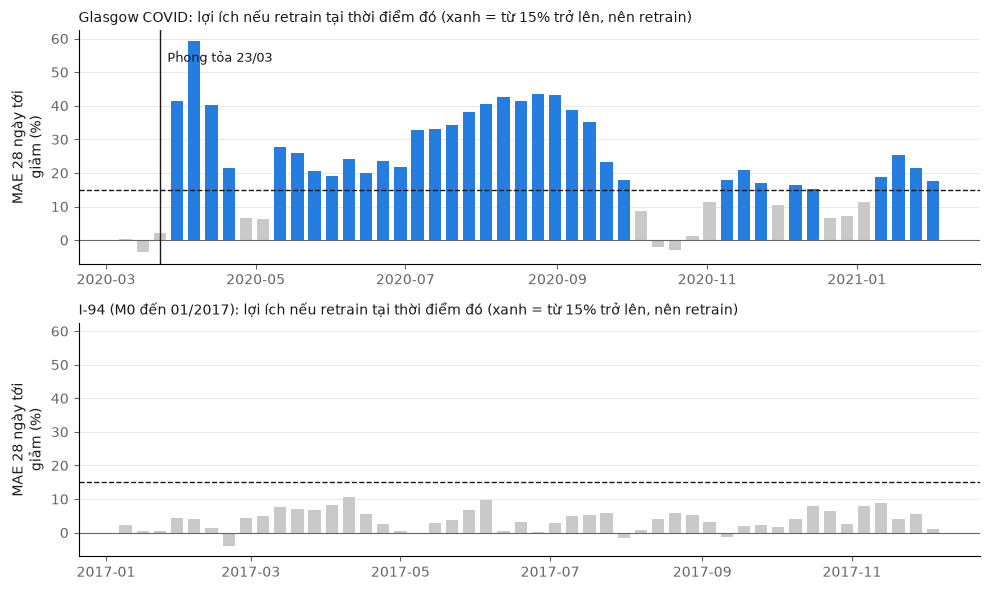

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharey=True)
for ax, name in zip(axes, ["Glasgow COVID", "I-94 (M0 đến 01/2017)"]):
    t = truths[name]
    colors = [BLUE if v else "#c9c9c9" for v in t.needs_retrain]
    ax.bar(t.index, 100 * t.gain, width=5, color=colors)
    ax.axhline(100 * GAIN, color=INK, lw=1, ls="--")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_title(f"{name}: lợi ích nếu retrain tại thời điểm đó (xanh = từ 15% trở lên, nên retrain)",
                 loc="left", fontsize=10, color=INK)
    ax.set_ylabel("MAE 28 ngày tới\ngiảm (%)", color=INK)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e5e5", lw=0.6)
    ax.set_axisbelow(True); ax.tick_params(colors=MUTED)
axes[0].axvline(LOCKDOWN, color=INK, lw=1)
axes[0].text(LOCKDOWN + pd.Timedelta(days=3), axes[0].get_ylim()[1] * 0.85, "Phong tỏa 23/03", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "E3-3-ground-truth-retrain-gain.png", dpi=150); plt.show()

**Đọc kết quả.**
- **Glasgow COVID:** ba thứ Hai đầu (09, 16, 23/03) retrain **chưa** giúp gì (lợi ích ≈ 0%) — vì dữ liệu mới nhất lúc đó vẫn là giao thông trước COVID. Thứ Hai **30/03**, một tuần sau phong tỏa, retrain giúp MAE 28 ngày tới **giảm 41%**; tuần sau đó **59%**. Sau đó đa số thời điểm đều "nên retrain" vì M0 (học 10/2019–02/2020) ngày càng lỗi thời.
- **Nơi ổn định** (I‑94 ba mốc, Glasgow 2022–2023): phần lớn thời điểm retrain giúp chưa tới 15% (lợi ích trung vị chỉ vài %). Ở đây một tín hiệu tốt phải **im lặng**.
- Đáp án có **điểm bắt đầu rõ** (30/03/2020) và **giai đoạn yên** để đo báo nhầm — đủ để chấm tín hiệu ở bước 5.3–5.4. So với bước 5.1: hệ thống hiện tại báo từ 08/03, **sớm 3 tuần so với lúc retrain bắt đầu có ích**, và báo cả trong mọi giai đoạn yên.

Đáp án được lưu ở `experiments/outputs/e3/truth_*.csv` để dùng lại.

### Tóm tắt bước 5.2

| Câu hỏi | Trả lời |
| --- | --- |
| "Nên retrain" nghĩa là gì? | Retrain ngay lúc đó (24 tháng gần nhất) làm MAE 28 ngày tới giảm ≥ 15% so với giữ model cũ |
| COVID ở Glasgow: khi nào bắt đầu nên retrain? | Thứ Hai 30/03/2020 (sau phong tỏa 1 tuần), lợi ích 41% |
| Nơi ổn định có nên retrain thường xuyên không? | Ít — xem bảng tóm tắt các tình huống ở trên |

**Bài học về phương pháp (bước 5.2)**
1. Muốn chấm một bộ phát hiện, phải có **đáp án định nghĩa bằng hậu quả** (retrain có làm sai số giảm không), không phải bằng chính tín hiệu đang được chấm.
2. **Kiểm tra đáp án trước khi dùng**: định nghĩa nháp cho gần nửa số tuần "nên retrain" ở nơi ổn định — vô lý, nên phải sửa.
3. Đáp án gắn với **một quyết định thật** (retrain hôm nay, hưởng lợi 4 tuần tới) dễ giải thích hơn đáp án theo từng tuần rời rạc.